# Experiment 3: Breadth-first and depth-first search
One search function, two algorithms; compared on cells expanded, path length and frontier size.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

## A carved maze (randomised depth-first carver, seeded)
Cells at odd coordinates are rooms; carving knocks out the wall between two rooms.
A perfect maze has exactly one path between any two cells, so a few extra walls are removed
(`loops`) to give the two searches a real choice of routes.

In [2]:
def carve_maze(h, w, seed=7, loops=25):
    rng = np.random.default_rng(seed)
    maze = np.ones((h, w), dtype=int)                 # 1 = wall, 0 = open
    stack = [(1, 1)]; maze[1, 1] = 0
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2)
                for dr, dc in ((-2, 0), (2, 0), (0, -2), (0, 2))
                if 0 < r + dr < h - 1 and 0 < c + dc < w - 1 and maze[r + dr, c + dc] == 1]
        if not nbrs:
            stack.pop(); continue
        nr, nc, wr, wc = nbrs[rng.integers(len(nbrs))]
        maze[wr, wc] = maze[nr, nc] = 0
        stack.append((nr, nc))
    removed = 0
    while removed < loops:                            # open some walls between rooms
        r, c = rng.integers(1, h - 1), rng.integers(1, w - 1)
        if maze[r, c] == 1 and ((r % 2 == 1 and c % 2 == 0) or (r % 2 == 0 and c % 2 == 1)):
            maze[r, c] = 0; removed += 1
    return maze

maze = carve_maze(23, 35)
H, W = maze.shape
START, GOAL = (1, 1), (H - 2, W - 2)
print("maze", maze.shape, "open cells:", int((maze == 0).sum()))

maze (23, 35) open cells: 398


## The implicit graph and the search

In [3]:
def neighbours(cell):
    r, c = cell
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):    # up, down, left, right
        nr, nc = r + dr, c + dc
        if 0 <= nr < H and 0 <= nc < W:                  # bounds first
            if maze[nr, nc] == 0:                        # then contents
                yield (nr, nc)

def search(start, goal, mode="bfs"):
    frontier = deque([start])
    parent = {start: None}            # marked on enqueue: also the 'seen' set
    order, frontier_size = {}, []
    while frontier:
        node = frontier.popleft() if mode == "bfs" else frontier.pop()   # the only difference
        order[node] = len(order)
        if node == goal:
            frontier_size.append(len(frontier)); break
        for nxt in neighbours(node):
            if nxt not in parent:
                parent[nxt] = node
                frontier.append(nxt)
        frontier_size.append(len(frontier))
    path, cur = [], goal if goal in parent else None
    while cur is not None:
        path.append(cur); cur = parent[cur]
    return order, path[::-1], frontier_size

def validate(path):
    ok_ends = path[0] == START and path[-1] == GOAL
    ok_steps = all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(path, path[1:]))
    ok_walls = all(maze[r, c] == 0 for r, c in path)
    return ok_ends and ok_steps and ok_walls

R = {"maze_shape": [H, W], "open_cells": int((maze == 0).sum())}
res = {}
for mode in ("bfs", "dfs"):
    order, path, fs = search(START, GOAL, mode)
    res[mode] = (order, path, fs)
    R[mode] = dict(expanded=len(order), path_cells=len(path), path_steps=len(path) - 1,
                   valid=validate(path), max_frontier=max(fs))
    print(mode.upper(), R[mode])

BFS {'expanded': 366, 'path_cells': 65, 'path_steps': 64, 'valid': True, 'max_frontier': 12}
DFS {'expanded': 94, 'path_cells': 81, 'path_steps': 80, 'valid': True, 'max_frontier': 16}


## Checks: BFS length is the true shortest; a broken path is rejected

In [4]:
def bfs_distance(start, goal):        # independent shortest-path check (plain BFS layer count)
    dist = {start: 0}; q = deque([start])
    while q:
        u = q.popleft()
        for v in neighbours(u):
            if v not in dist:
                dist[v] = dist[u] + 1; q.append(v)
    return dist[goal]

assert bfs_distance(START, GOAL) == R["bfs"]["path_steps"]
bad = list(res["bfs"][1]); bad[len(bad) // 2] = (0, 0)   # corrupt one step: must fail validation
assert not validate(bad)
print("checks passed")

checks passed


## Figures

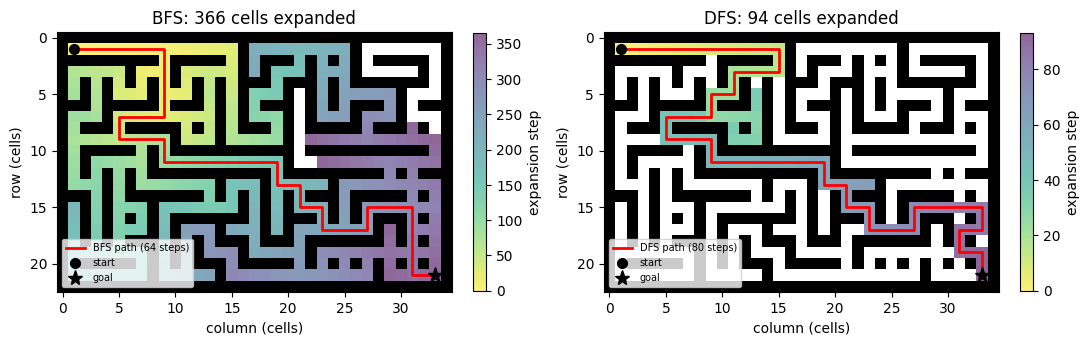

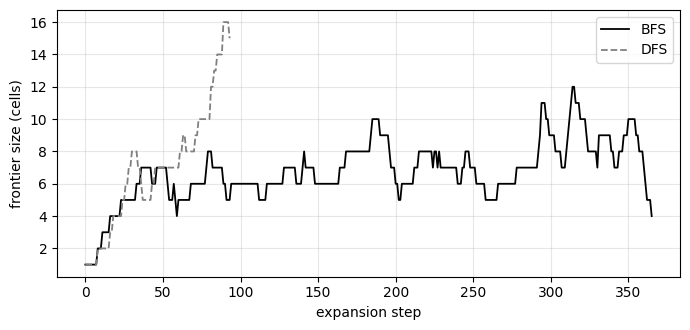

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, mode in zip(axes, ("bfs", "dfs")):
    order, path, _ = res[mode]
    grid = np.full(maze.shape, np.nan)
    for (r, c), k in order.items():
        grid[r, c] = k
    ax.imshow(maze, cmap="binary", extent=(-0.5, W - 0.5, H - 0.5, -0.5))
    im = ax.imshow(grid, cmap="viridis_r", alpha=0.6)
    ax.plot([c for _, c in path], [r for r, _ in path], lw=2, color="r",
            label=f"{mode.upper()} path ({len(path) - 1} steps)")
    ax.plot(*START[::-1], "o", color="k", ms=7, label="start")
    ax.plot(*GOAL[::-1], "*", color="k", ms=11, label="goal")
    ax.set(title=f"{mode.upper()}: {len(order)} cells expanded", xlabel="column (cells)", ylabel="row (cells)")
    ax.legend(fontsize=7, loc="lower left")
    fig.colorbar(im, ax=ax, fraction=0.03, label="expansion step")
fig.tight_layout(); fig.savefig("figs/fig3_1_maze_paths.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.4))
for mode, st in (("bfs", "-"), ("dfs", "--")):
    ax.plot(res[mode][2], st, color="k" if mode == "bfs" else "0.5", lw=1.3, label=mode.upper())
ax.set(xlabel="expansion step", ylabel="frontier size (cells)")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig("figs/fig3_2_frontier.png", dpi=150); plt.show()

In [6]:
json.dump(R, open("results.json", "w"), indent=1)